# DSC 210 Exam 2: Take-home portion

**DSC 210 Foundations of Data Science**

Covers Modules 8 to 11. Worth 30 of the exam's 100 points.

```
ASK  ->  GET  ->  [ EXPLORE ]  ->  MODEL  ->  COMMUNICATE
```

References:
- Data: "fishcatch," submitted by Juha Puranen (University of Helsinki) to the *Journal of Statistics Education* data archive, https://jse.amstat.org/datasets/fishcatch.txt (description) and `fishcatch.dat` (data). Original source: Pekka Brofeldt (1917), "Bidrag till kännedom om fiskbeståndet i våra sjöar. Längelmävesi," in T. H. Järvi, *Finlands Fiskerier*, Band 4. Our copy, `csv_data/fishcatch.csv`, keeps the archive's values and codes.

## Instructions

**Total: 30 points.** Plan on about 1.5 to 2 hours.

- This is an exam: work **alone**. You may use your course notebooks, your homework, and the pandas, seaborn, and scikit-learn documentation. You may not discuss the exam with anyone or use a generative AI tool.
- Use only methods from the course. Cells marked `RUN-TOGETHER` are complete: run them and read the output. Cells marked with a problem number are yours to fill in.
- Every figure needs a title and labeled axes (the figures we draw for you already have them).
- Most of the credit rides on your written answers. **Quote specific numbers from your output.** One or two specific sentences beat a long, general paragraph.
- Submit the completed `.ipynb`, with all cells run and all figures visible, to Canvas.

## The scenario and the data

In 1917 a Finnish researcher caught and measured 159 fish of seven species from Längelmävesi, a lake near Tampere, Finland. A fisheries office wants to know three things: **do the species fall into natural body types, can a fish's species be identified from its measurements, and how well can a fish's weight be predicted from its length?** (In the field, length is quick to measure; weight needs a scale and a calm boat.)

| Column | Meaning |
| --- | --- |
| `obs` | fish number, 1 to 159 |
| `species` | species code, 1 to 7 (names are in a separate table) |
| `weight` | weight (grams) |
| `length1` | length from the nose to the beginning of the tail (cm) |
| `length2` | length from the nose to the notch of the tail (cm) |
| `length3` | length from the nose to the end of the tail (cm) |
| `height_pct` | greatest body height, **as a percentage of `length3`** |
| `width_pct` | greatest body width, **as a percentage of `length3`** |
| `sex` | 1 = male, 0 = female |

A note on names: the source lists species 4 (*Abramis bjoerkna*) without an English name; we use its Finnish name, *parkki* (in English it is usually called the silver bream). The source calls species 2 "whitefish" but gives the Latin name *Leuciscus idus*, a fish usually called the ide in English. We keep the source's name.

In [1]:
# RUN-TOGETHER  (setup)
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

url = 'https://raw.githubusercontent.com/jppeirce/DSC210-Foundations-of-Data-Science/main/csv_data/'
fish = pd.read_csv(url + 'fishcatch.csv')

species = pd.DataFrame({
    'species': [1, 2, 3, 4, 5, 6, 7],
    'name':    ['Bream', 'Whitefish', 'Roach', 'Parkki', 'Smelt', 'Pike', 'Perch'],
    'latin':   ['Abramis brama', 'Leuciscus idus', 'Leuciscus rutilus', 'Abramis bjoerkna',
                'Osmerus eperlanus', 'Esox lucius', 'Perca fluviatilis'],
})
print('fish:', fish.shape)
fish.head()

fish: (159, 9)


,obs,species,weight,length1,length2,length3,height_pct,width_pct,sex
0,1,1,242.0,23.2,25.4,30.0,38.4,13.4,NaN
1,2,1,290.0,24.0,26.3,31.2,40.0,13.8,NaN
2,3,1,340.0,23.9,26.5,31.1,39.8,15.1,NaN
3,4,1,363.0,26.3,29.0,33.5,38.0,13.3,NaN
4,5,1,430.0,26.5,29.0,34.0,36.6,15.1,NaN


---
## Problem 1. Getting the fish ready (6 points)
---

**(a) (2 points)** Merge `fish` with `species` so that every fish gets its species `name`, and store the result back in `fish`. Which join type did you choose, and why is it the safe choice here? Confirm that no fish was lost or left without a name, and report how many fish of each species there are.

In [2]:
# Problem 1(a): your code here
print('Num of Fish before merge:', len(fish))
fish = pd.merge(fish, species, how='inner')
print('Num of Fish after merge:',len(fish))
print('Num of Fish without a name:',fish['name'].isna().sum())
print('Num of fish of each species:', '\n' ,fish['name'].value_counts())


Num of Fish before merge: 159
Num of Fish after merge: 159
Num of Fish without a name: 0
Num of fish of each species: 
 name
Perch        56
Bream        35
Roach        20
Pike         17
Smelt        14
Parkki       11
Whitefish     6
Name: count, dtype: int64


**Your answer:**
I chose to use an inner merge. This is a safe choise because it ensures each fish will have a species name; each value is present in both columns. Because of this, I checked to make sure no rows were lost from the merge.


**(b) (2 points)** Find the missing values in every column. Then look for a **disguised** missing value in `weight` (hint: `describe()`, then a boolean mask). Which fish are affected, and what should be done with them **before Problem 4, where weight is the label we predict**? Explain why imputing their weights would be a poor choice there.

In [3]:
# Problem 1(b): your code here
print(fish.isna().sum())
print(fish['weight'].describe())
print((fish['weight'] == 0).sum())

obs            0
species        0
weight         1
length1        0
length2        0
length3        0
height_pct     0
width_pct      0
sex           87
name           0
latin          0
dtype: int64
count     158.000000
mean      398.695570
std       359.086204
min         0.000000
25%       120.000000
50%       272.500000
75%       650.000000
max      1650.000000
Name: weight, dtype: float64
1


**Your answer:** Fish with n/a values or weight equal to zero are missing values and they should be deleted rather than imputed because the weight is the subject of our question: "how well can a fish's weight be predicted from its length?" We should never impute the variable that is the subject of your study, as it could be seen as manufacrturing evidence.



**(c) (2 points)** Make a crosstab of species `name` against whether `sex` is missing. Is the missingness in `sex` random or systematic? Explain what the pattern suggests about how the data were recorded, and decide whether `sex` should be used as a feature in this exam.

In [4]:
# Problem 1(c): your code here
print(pd.crosstab(fish['name'], fish['sex'].isna()))

sex        False  True 
name                   
Bream          9     26
Parkki         7      4
Perch         27     29
Pike           6     11
Roach          8     12
Smelt         14      0
Whitefish      1      5


**Your answer:**
 The crosstab shows that the missing values are not spread evenly across species. The missingness in sex is systematic. This suggests that the present data is biased. Sex should not be used as a feature in this exam because its systematic missingness will bias the data.



The cell below records our cleaning decisions and builds the table used in the rest of the exam: it turns the disguised 0 into `NaN`, sets aside the 2 fish with no usable weight, and converts height and width from percentages of `length3` into centimeters (the formula comes with the data).

In [5]:
# RUN-TOGETHER  (cleaning decisions)
fish.loc[fish['weight'] == 0, 'weight'] = np.nan          # Decision 1: a 0 g fish is a disguised missing value
fish_clean = fish.dropna(subset=['weight']).copy()        # Decision 2: set aside the 2 fish with no usable weight
fish_clean['height_cm'] = fish_clean['height_pct'] * fish_clean['length3'] / 100   # Decision 3: percentages to cm
fish_clean['width_cm'] = fish_clean['width_pct'] * fish_clean['length3'] / 100
                                                          # Decision 4: sex is not used (Problem 1c)
print('fish in fish_clean:', len(fish_clean))

fish in fish_clean: 157


---
## Problem 2. Body shape or body size? (8 points)
---

We now hide the species names and ask what structure the measurements contain on their own. There are two kinds of measurement here:

- **shape:** `height_pct` and `width_pct` describe the *proportions* of a fish, whatever its size;
- **size:** `length3`, `height_cm`, and `width_cm` grow as a fish grows.

In [6]:
# RUN-TOGETHER  (setup for Problem 2)
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

shape_features = ['height_pct', 'width_pct']
size_features = ['length3', 'height_cm', 'width_cm']
X_shape = StandardScaler().fit_transform(fish_clean[shape_features])
X_size = StandardScaler().fit_transform(fish_clean[size_features])

**(a) (2 points)** Draw an elbow plot of WCSS for k-means on `X_shape`, for k = 1 to 7 (use `n_init=10, random_state=210`). Which k does it suggest? Support your choice with the drops in WCSS.

k = 1   WCSS =   314.0
k = 2   WCSS =   128.0
k = 3   WCSS =    45.6
k = 4   WCSS =    25.2
k = 5   WCSS =    20.1
k = 6   WCSS =    16.8


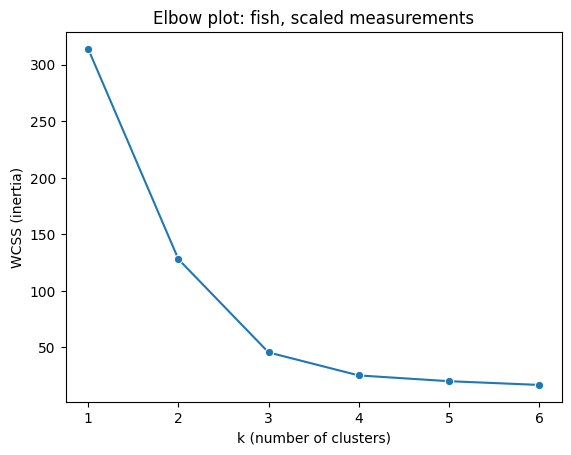

In [7]:
# Problem 2(a): your code here
ks = range(1, 7)
wcss = [KMeans(n_clusters=k, n_init=10, random_state=210).fit(X_shape).inertia_ for k in ks]

for k, w in zip(ks, wcss):
    print(f'k = {k}   WCSS = {w:7.1f}')

sns.lineplot(x=list(ks), y=wcss, marker='o')
plt.title('Elbow plot: fish, scaled measurements')
plt.xlabel('k (number of clusters)')
plt.ylabel('WCSS (inertia)')
plt.xticks(list(ks))
plt.show()

**Your answer:**
The elbow plot suggests k=3, the change in k is signficantly less for k above 3 in comparison to k below 3. From 2-3 the drop in WCSS is 82.4; from 3-4 the drop is 10.4.



**(b) (2 points)** Fit k-means with **k = 3** on `X_shape`, store the labels in `fish_clean['shape_cluster']`, and crosstab species `name` against the clusters. Also print the mean `height_pct` and `width_pct` of each cluster. Describe each cluster as a **body type** and say which species it contains.

In [8]:
# Problem 2(b): your code here
km_fish = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X_shape)
fish_clean['shape_cluster'] = km_fish.labels_

print('species crosstab:','\n')
print(pd.crosstab(fish_clean['name'], fish_clean['shape_cluster']))
print('\nmean height_pct and width_pct:','\n')
print(fish_clean.groupby('shape_cluster')[['height_pct', 'width_pct']].mean().round(1))

species crosstab: 

shape_cluster   0   1   2
name                     
Bream           0   0  34
Parkki          0   0  11
Perch           0  56   0
Pike           17   0   0
Roach           0  19   0
Smelt          13   1   0
Whitefish       0   6   0

mean height_pct and width_pct: 

               height_pct  width_pct
shape_cluster                       
0                    16.2       10.2
1                    26.5       15.5
2                    39.5       14.1


**Your answer:**
The clusters seperate the fish into 3 body types. Cluster zero is very thin body type with low height and width. Cluster one is medium body type with both normally tall height and average width. Cluster two is tall body type with very tall fish with normal width---resulting in flater fish.


**(c) (2 points)** Run the cell below, which repeats k-means with k = 3 on the **size** features instead. Do these clusters match species? What did k-means find instead, and why? Connect your answer to the penguin case study ("species, sex, or size?").

In [9]:
# RUN-TOGETHER  (Problem 2c)
km_size = KMeans(n_clusters=3, n_init=10, random_state=210).fit(X_size)
fish_clean['size_cluster'] = km_size.labels_
print(pd.crosstab(fish_clean['name'], fish_clean['size_cluster']))
print()
print(fish_clean.groupby('size_cluster')[['length3', 'weight']].mean().round(0))

size_cluster   0   1   2
name                    
Bream          2  32   0
Parkki         9   0   2
Perch         32  19   5
Pike           8   9   0
Roach         17   1   1
Smelt          0   0  14
Whitefish      3   3   0

              length3  weight
size_cluster                 
0                27.0   194.0
1                42.0   761.0
2                14.0    23.0


**Your answer:**
This clusters the fish on age rather than size. The fish of each species is spread across each of the clusters. The clusters group based on weight. This suggests that there are different weights among each species---this represents the age groups. Each cluster shows child, teen, and, adult fish. This connects to how k-means did not find species for the penguin; it found size.


**(d) (2 points)** Fit PCA to the six scaled measurements `['weight', 'length1', 'length2', 'length3', 'height_cm', 'width_cm']` and print the share of variance for each component and the PC1 and PC2 loadings. Then run the cell after yours, which shows each species' average PC1 and PC2 scores.

1. PC1 alone explains a very large share. Name PC1, and explain why one component can summarize six measurements so well.
2. Name PC2 from its loadings, and say which species score highest and lowest on it. Does that agree with part (b)?

In [10]:
# Problem 2(d): your code here (create pca and pcs)
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

measurements = ['weight', 'length1', 'length2', 'length3', 'height_cm', 'width_cm']
X_scaled = StandardScaler().fit_transform(fish_clean[measurements])

pca = PCA()
pcs = pca.fit_transform(X_scaled)

share = pca.explained_variance_ratio_
print('share      :', share.round(3))
print('cumulative :', share.cumsum().round(3))

loadings = pd.DataFrame(pca.components_[:2], index=['PC1', 'PC2'], columns=measurements)
print('\nPC1 and PC2 loadings:')
print(loadings.round(3))

share      : [0.879 0.085 0.02  0.016 0.    0.   ]
cumulative : [0.879 0.964 0.984 1.    1.    1.   ]

PC1 and PC2 loadings:
     weight  length1  length2  length3  height_cm  width_cm
PC1   0.418    0.421    0.423    0.428      0.343     0.410
PC2  -0.034   -0.336   -0.310   -0.200      0.841     0.205


In [11]:
# RUN-TOGETHER  (Problem 2d: average scores by species; needs pcs from your cell)
scores = pd.DataFrame({'name': fish_clean['name'].to_numpy(), 'PC1': pcs[:, 0], 'PC2': pcs[:, 1]})
print(scores.groupby('name')[['PC1', 'PC2']].mean().round(2).sort_values('PC2'))

            PC1   PC2
name                 
Pike       2.43 -1.53
Smelt     -3.70 -0.37
Perch     -0.14 -0.11
Roach     -1.34 -0.04
Whitefish  0.83  0.11
Parkki    -1.53  0.51
Bream      1.63  0.94


**Your answer:**
PC1 seems to measure the total overall size of the fishes based on the output. PC1 has a significant loading value in each of the measurments. This summarizes the six measurements well as one overall value. PC2 seems to measure body type. PC2 has large loading values in height and width, which were used in §2b to describe the body type. Bream scores highest and Pike scores lowest. This matches up with our data from §2b.



---
## Problem 3. Which species is it? (8 points)
---

A field technician measures a fish and wants software to name its species. Features: `weight`, `length3`, `height_pct`, `width_pct` (a mix of size and shape). Label: `name`.

In [12]:
# RUN-TOGETHER  (setup for Problem 3)
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

features = ['weight', 'length3', 'height_pct', 'width_pct']
X = fish_clean[features]
y = fish_clean['name']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=210, stratify=y)
print('training fish:', len(X_train), '  test fish:', len(X_test))
print(y_test.value_counts())

training fish: 109   test fish: 48
name
Perch        17
Bream        11
Roach         6
Pike          5
Smelt         4
Parkki        3
Whitefish     2
Name: count, dtype: int64


**(a) (1 point)** What test accuracy does the study map's baseline (always guess the most common species) achieve?

In [13]:
# Problem 3(a): your code here
round(17/48,3) # 17 Perch out of 48 test fish


0.354

**Your answer:**
The accuracy will be 0.354 if the model always guess the most common species---which is perch.



**(b) (2 points)** Fit k-NN with `k = 5` on the raw features and on scaled features (fit the scaler on the **training** data only). Report both test accuracies and explain the difference. Which feature controls the unscaled distances, and why does that hurt here?

In [14]:
# Problem 3(b): your code here
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)
knn = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, y_train)
pred_knn = knn.predict(X_test_s)

print('test accuracy, scaled  :', round(knn.score(X_test_s, y_test), 3))

knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print('test accuracy, unscaled:', round(knn_raw.score(X_test, y_test), 3))

print('\n',X_train.describe().round(1))

test accuracy, scaled  : 0.854
test accuracy, unscaled: 0.542

        weight  length3  height_pct  width_pct
count   109.0    109.0       109.0      109.0
mean    412.0     31.4        28.2       14.0
std     378.5     12.5         8.3        2.2
min       5.9      8.8        14.5        8.7
25%     120.0     22.5        24.1       13.3
50%     272.0     29.4        27.2       14.6
75%     685.0     40.5        37.8       15.4
max    1650.0     68.0        41.5       18.1


**Your answer:**
Both accuricies are listed above, the difference in scaled and unscaled data is due to large ranges of data in certain varriables compared to others. Variables with larger ranges will create greater distances between values in the train data, and will hurt the accuracy for the test. The feature that hurts the accuracy of the test is the weight. As explained earlier fish of different species can have the same weight, this will especially hurt test accuracy.


**(c) (2 points)** Fit a decision tree with no `max_depth` (`random_state=0`) and report its training and test accuracy. Then fit a random forest (`n_estimators=300, random_state=0`) and report its test accuracy. Explain the tree's gap between training and test accuracy, and explain how the forest's **two sources of randomness** and its **majority vote** address that weakness.

In [15]:
# Problem 3(c): your code here
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

tree = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
print('Tree:\ntrain accuracy:', round(tree.score(X_train, y_train), 3))
print('test accuracy:', round(tree.score(X_test, y_test), 3))

forest = RandomForestClassifier(n_estimators=300, random_state=0).fit(X_train, y_train)
print('\nForest:\ntrain accuracy:', round(forest.score(X_train, y_train), 3))
print('test accuracy:', round(forest.score(X_test, y_test), 3))

Tree:
train accuracy: 1.0
test accuracy: 0.792

Forest:
train accuracy: 1.0
test accuracy: 0.812


**Your answer:**
With no max depth, the tree keeps training until it overfits the data, and guesses the test based exactly on the train. The forest uses random trees and random splits for each tree. These sources of randomness give a variety of random overfit trees. The majority vote fixes the weakness of overfitting by finding the average among the trees, reducing errors and increasing accuracy.



**(d) (3 points)** Print the random forest's confusion matrix with `labels=labels` (defined in the cell), and its overall test accuracy. Then:

1. Compute, from the matrix, the **recall** for whitefish and for parkki, and the **precision** for bream.
2. Which species are confused with each other? Use your answers to Problem 2(b) to explain why those mistakes are the ones you would expect.
3. Explain why the overall accuracy hides the model's weakness on rare species.

In [16]:
# Problem 3(d): your code here
labels = ['Bream', 'Parkki', 'Perch', 'Pike', 'Roach', 'Smelt', 'Whitefish']
from sklearn.metrics import confusion_matrix, classification_report

pred_forest = forest.predict(X_test)

cm = confusion_matrix(y_test, pred_forest, labels=labels)
print(pd.DataFrame(cm, index=labels, columns=labels))
print('\ntest accuracy:', round(forest.score(X_test, y_test), 3))



           Bream  Parkki  Perch  Pike  Roach  Smelt  Whitefish
Bream         11       0      0     0      0      0          0
Parkki         2       1      0     0      0      0          0
Perch          0       0     15     0      2      0          0
Pike           0       0      0     5      0      0          0
Roach          0       0      3     0      3      0          0
Smelt          0       0      0     0      0      4          0
Whitefish      0       0      2     0      0      0          0

test accuracy: 0.812


**Your answer:**
Recall for whitefish: 0/2 ; Recall for Parkki: 1/3 ; Precision for bream: 11/13. Bream and parkki are confused with eachother. Perch, Roach, and Whitefish  are confused with eachother. This makes sense because these confused species are  in the same body type cluster from question 2b. The overall accurcy hides the weakness on rare species because the high quantities of the common fish in the test set keep a higher overall accuracy.



---
## Problem 4. How heavy is a fish? (8 points)
---

Weight is the label now, so we use `fish_clean`, which already excludes the two fish without a usable weight.

In [17]:
# RUN-TOGETHER  (setup for Problem 4)
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Xr = fish_clean[['length3']]
yr = fish_clean['weight']
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.25, random_state=210)
print('length3 ranges from', Xr['length3'].min(), 'to', Xr['length3'].max(), 'cm')

length3 ranges from 8.8 to 68.0 cm


**(a) (2 points)** Fit a linear regression of `weight` on `length3` using the training data. Report the slope and intercept and interpret the slope in context, with units. Then use the line to predict the weight of a **10 cm** fish. Explain what is wrong with that prediction, and why it is a different problem from the intercept being impossible.

In [18]:
# Problem 4(a): your code here
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lin = LinearRegression().fit(Xr_train, yr_train)
pred = lin.predict(Xr_test)
print('slope    :', round(lin.coef_[0], 2), 'g per cm')
print('intercept:', round(lin.intercept_, 2), 'g')
print('wt of 10 cm fish:', round(lin.coef_[0] * 10 + lin.intercept_, 2), 'g')


slope    : 28.03 g per cm
intercept: -472.75 g
wt of 10 cm fish: -192.41 g


**Your answer:**
slope: 28.03 g per cm ; intercept: -472.75 g. The slope means that for every additional cm a fish has It will have an aditional 28.03 g of weight. The regression line predicts a fish with negative weight, even when the length is within the given range. This is because the line is more inacurate at lower weights. The true relationship line is likely curved rather than linear. The linear line is biased by the stronger corelation towards the high values and projects the line into the negative weights at lower values. This differs from the intercept because the intercept is impossible because it is outside the specified range of the dataset: 8.8 to 68.0 cm.


**(b) (2 points)** Evaluate the line on the test set (MAE, RMSE, $R^2$). Then run the residual-plot cell. Describe the pattern, and explain why a model with this $R^2$ can still be the wrong shape. (Think about how weight should grow as a fish of the same proportions gets longer.)

In [19]:
# Problem 4(b): your code here (metrics)

mae = mean_absolute_error(yr_test, pred)
rmse = np.sqrt(mean_squared_error(yr_test, pred))
r2 = r2_score(yr_test, pred)
print('MAE:',round(mae, 2),'g')
print('RMSE:',round(rmse, 2),'g')
print('R2 :',round(r2, 3))

MAE: 93.17 g
RMSE: 122.67 g
R2 : 0.881


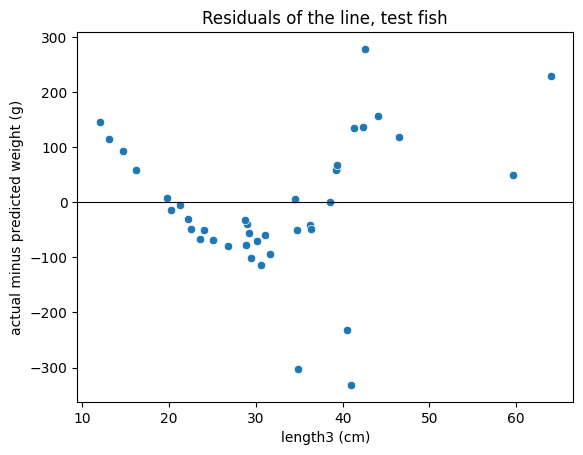

           mean  count
length3               
(0, 20]    84.0      5
(20, 30]  -51.0     13
(30, 40]  -45.0     13
(40, 50]   37.0      7
(50, 70]  139.0      2


In [20]:
# RUN-TOGETHER  (Problem 4b: residuals; needs line from 4a)
resid = pd.DataFrame({'length3': Xr_test['length3'],
                      'residual': yr_test - lin.predict(Xr_test)})
sns.scatterplot(data=resid, x='length3', y='residual')
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Residuals of the line, test fish')
plt.xlabel('length3 (cm)'); plt.ylabel('actual minus predicted weight (g)')
plt.show()

bands = pd.cut(resid['length3'], [0, 20, 30, 40, 50, 70])
print(resid.groupby(bands, observed=True)['residual'].agg(['mean', 'count']).round(0))

**Your answer:**
The plot shows that the short and long fish have positve resudals and the medium fish have negative. This is a curved residual pattern. The ideal pattern is a random scattering around the line. R2 detects the overall trend, but it is not able to detect the errors from curvature. If a fish of equal proportions gets longer, its weight is exponetially scaled. This is further evidence towards a curved line.


**(c) (4 points)** The cell below does two things. It draws the fits of four models that use `length3` alone, and it compares the same four kinds of model using **three** features (`length3`, `height_cm`, `width_cm`) with shuffled 5-fold cross-validation on all 157 fish. Describe the shape of each fit, then choose a model for the fisheries office using the cross-validation results. Justify your choice with the mean **and** the spread of the fold scores.

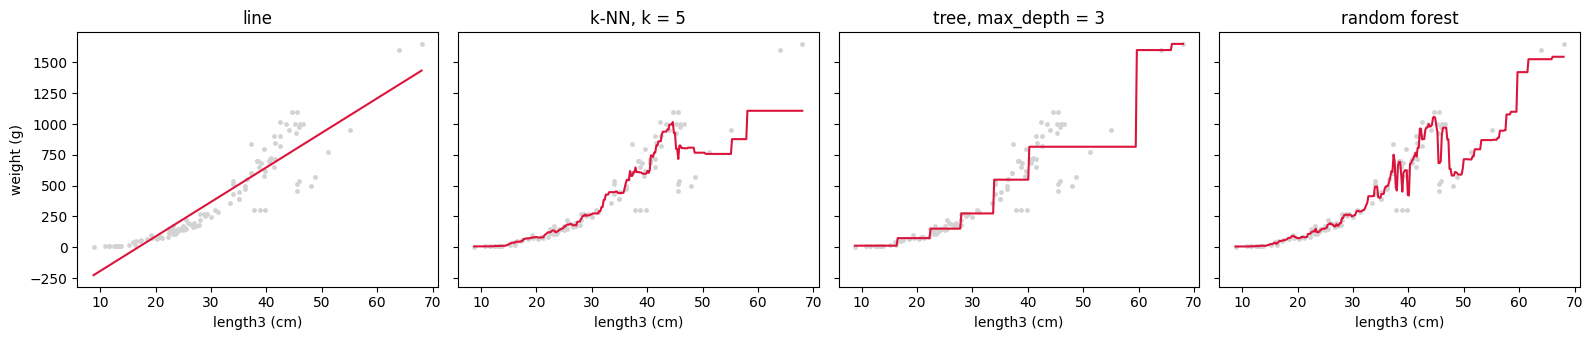

                line: mean R2 = 0.850   folds [0.886 0.81  0.826 0.854 0.871]
         k-NN, k = 5: mean R2 = 0.941   folds [0.944 0.925 0.95  0.967 0.922]
 tree, max_depth = 3: mean R2 = 0.931   folds [0.911 0.942 0.96  0.924 0.917]
       random forest: mean R2 = 0.977   folds [0.977 0.985 0.986 0.974 0.962]


In [21]:
# RUN-TOGETHER  (Problem 4c: about 15 seconds)
models = {'line': LinearRegression(),
          'k-NN, k = 5': KNeighborsRegressor(n_neighbors=5),
          'tree, max_depth = 3': DecisionTreeRegressor(max_depth=3, random_state=0),
          'random forest': RandomForestRegressor(n_estimators=200, random_state=0)}

grid_len = pd.DataFrame({'length3': np.linspace(Xr['length3'].min(), Xr['length3'].max(), 300)})
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, (name, m) in zip(axes, models.items()):
    m.fit(Xr_train, yr_train)
    ax.scatter(Xr_train['length3'], yr_train, s=6, color='lightgray')
    ax.plot(grid_len['length3'], m.predict(grid_len), color='crimson')
    ax.set_title(name); ax.set_xlabel('length3 (cm)')
axes[0].set_ylabel('weight (g)')
plt.tight_layout()
plt.show()

X3 = fish_clean[['length3', 'height_cm', 'width_cm']]
kf = KFold(5, shuffle=True, random_state=210)
for name, m in models.items():
    s = cross_val_score(m, X3, yr, cv=kf, scoring='r2')
    print(f'{name:>20}: mean R2 = {s.mean():.3f}   folds {np.round(s, 3)}')

**Your answer:**
The linear regression is a straight line that fails to capture the curve. The kNN follows the data but flattens out towards the end. The tree has a staircase style fit with constant values across each step. the random forest follows the data near to each point along the range. The random forest is the best model for the fisheries office. This is because it has the highest R2 performance accuracy of 97.7%. It also has the shortest range across the folds among the selected model: 0.962 to 0.986, spread: 0.024.


---
*End of the take-home portion. Before submitting: Kernel > Restart & Run All, then check that every figure appears and every answer cell is filled in.*